We would like to extend similarity-based Lesk algorithm to include phonetic matching, which evaluates phonetically similar wording. For this purpose, use the “Fuzzy” library in python to generate the character string that identifies phonetically similar words, and then use edit distance to compute the phonetic similarity between two words. See an example of implementation at https://www.analyticsvidhya.com/blog/2017/01/ultimate-guide-to-understand-implement-natural-language-processing-codes-in-python/. Demonstrate this reasoning on the example sentence pointed out in 1) and generate a matrix that indicates the phonetic distance between each pair of words of the sentence.

In [23]:
import utils as u
import numpy as np
import matplotlib.pyplot as plt

SENTENCE = "I have been prescribed two important drugs today during my visit to clinic"
TARGET = 'drugs'

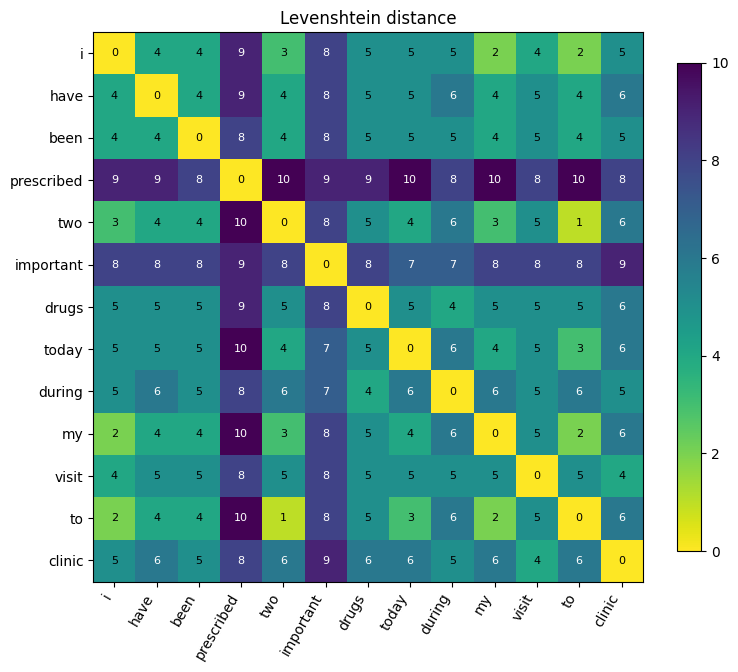

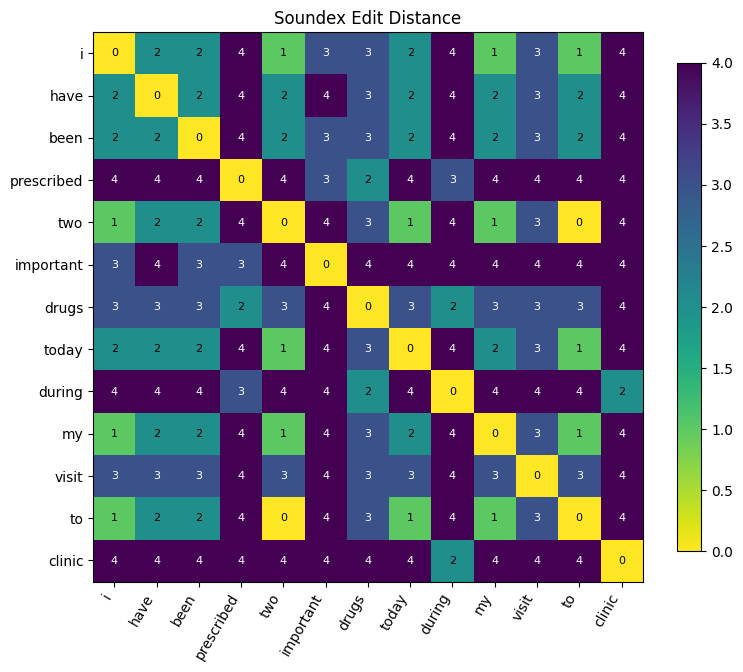

In [24]:
tokens = [w.lower() for w in SENTENCE.split()]

def levenshtein_matrix(words):
    """ Returns the matrix representation of all the permutations of levenshtein dinstances of the words in the given vector """
    n = len(words)
    matrix = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(i + 1, n):
            matrix[i, j] = matrix[j, i] = u.levenshtein(words[i], words[j])

    return matrix

def levenshtein_soundex_matrix(words):
    """ Returns the matrix representation of all the permutations of levenshtein dinstances of the soundex output of words in the given vector """
    n = len(words)
    matrix = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(i + 1, n):
            matrix[i, j] = matrix[j, i] = u.levenshtein(u.soundex(words[i]), u.soundex(words[j]))

    return matrix

def plot_matrix(matrix, words, title="Levenshtein distance"):
    """Show a distance matrix as a heatmap, with the value written in each cell."""
    fig, ax = plt.subplots(figsize=(8, 7))
    image = ax.imshow(matrix, cmap="viridis_r")
 
    ax.set_xticks(range(len(words)), words, rotation=60, ha="right")
    ax.set_yticks(range(len(words)), words)
 
    for i in range(len(words)):
        for j in range(len(words)):
            color = "white" if matrix[i, j] > matrix.max() / 2 else "black"
            ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=8, color=color)
 
    ax.set_title(title)
    fig.colorbar(image, ax=ax, shrink=0.8)
    fig.tight_layout()
    plt.show()

# Analysis
lev_dist = levenshtein_matrix(tokens)
lev_soundex_dist = levenshtein_soundex_matrix(tokens)

plot_matrix(lev_dist, tokens)
plot_matrix(lev_soundex_dist, tokens, title="Soundex Edit Distance")
